# WSDOT Linear Referencing Notebook
---
---

In [ ]:
from pathlib import Path
import os
from dotenv import load_dotenv
import pandas as pd
import geopandas as gpd
import psycopg
for candidate in (Path.cwd() / ".env", Path.cwd().parent / ".env"):
    if candidate.exists():
        load_dotenv(candidate)
        break
else:
    load_dotenv()
import os
from urllib.parse import quote_plus
from dotenv import load_dotenv
import folium
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

load_dotenv()

user = quote_plus(os.environ["DB_USERNAME"])
password = quote_plus(os.environ["DB_PASSWORD"])
host = os.environ.get("DB_HOST", "127.0.0.1")
port = os.environ.get("DB_PORT", "5432")
dbname = os.environ["DB_NAME"]

# For psycopg / psql
database_url = f"postgresql://{user}:{password}@{host}:{port}/{dbname}"

# For SQLAlchemy
sqlalchemy_url = f"postgresql+psycopg://{user}:{password}@{host}:{port}/{dbname}"

assert database_url, "DATABASE_URL not found in environment or .env"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)


def query_df(sql: str, params: tuple | dict | None = None) -> pd.DataFrame:
    with psycopg.connect(database_url) as conn:
        return pd.read_sql_query(sql, conn, params=params)


def query_gdf(sql: str, geom_col: str = "geom", params: tuple | dict | None = None) -> gpd.GeoDataFrame:
    with psycopg.connect(database_url) as conn:
        return gpd.read_postgis(sql, conn, geom_col=geom_col, params=params)

### Create dataframe out of view comparing derived ARM vs recorded WSDOT ARM

In [42]:
bridge_tunnel = query_gdf("""
SELECT *
FROM qa.vw_bt_arm_sensitivity
""", geom_col='geom')

#list(bridge_tunnel.columns)

## Arm Sensitivity table format
<div style="display: grid; grid-template-columns: repeat(3, minmax(0, 1fr)); gap: 24px;">

<div>

### Structure & Dimensions

- `objectid`
- `structureid`
- `structurenumber`
- `structurename`
- `structurelocation`
- `owner`
- `maintenanceresponsibility`
- `countyname`
- `cityname`
- `placecode`
- `federalortriballandsaccess`
- `emergevacdesignation`
- `hwyagencydistrict`
- `metroplanningorg`
- `section`
- `township`
- `range`
- `tollbridge`
- `historicsignificancenrhp`
- `historicalsignificancehaer`
- `yearbuilt`
- `snbireportflag`
- `sntireportflag`
- `structurelengthbyfeet`
- `maximumspanlengthbyfeet`
- `nbisscreeninglengthby10th`
- `calculateddeckareaby10th`
- `irregulardeckareaby10th`
- `minimumspanlengthbyfeet`
- `outtooutwidthfeetand10th`
- `curbtocurbwidthfeetand10th`
- `leftcurborsidewalkwidthby10th`
- `rightcurborsidewalkwidthby10th`
- `apprrdwywidthby10th`
- `bridgemedian`
- `bridgeskewdegree`
- `curvedbridge`
- `maxbridgeheightfeet`
- `sidehillbridge`
- `minvertclrncoverdeck`
- `minvertclrncunderbridge`
- `routinepermitloads`
- `designload`

</div>

<div>

### Condition, Inspection & Route Identification

- `loadpostingstatus`
- `bridgerailingscondition`
- `bridgerailtransitionscondition`
- `bridgejointscondition`
- `bridgebearingscondition`
- `deckoverallcondition`
- `superstructureoverallcondition`
- `substructureoverallcondition`
- `culvertcondition`
- `overallbridgecondition`
- `scourcondition`
- `channelcondition`
- `channelprotectioncondition`
- `scourvulnerability`
- `scourplanofaction`
- `overtoppinglikelihood`
- `apprrdwyalignment`
- `seismicvulnerability`
- `numberofutilites`
- `inspectionfrequency`
- `inspectiondate`
- `inspectionduedate`
- `mainlistingcode`
- `onundercode`
- `crossingdescription`
- `featurename`
- `featuretype`
- `featuredesignation`
- `featurelocation`
- `latitude`
- `longitude`
- `routenumber`
- `routemilepost`
- `routedirection`
- `routetype`
- `routeservicetype`
- `lrsrouteid`
- `lrsmilepost`
- `lrsaheadbackindicator`
- `lrsarm`
- `lrsinventorydirection`
- `lrsdate`
- `lrslanesonhighway`

</div>

<div>

### Clearances, Tunnel & QA Attributes

- `hwymaxusablevertclrnc`
- `hwyminvertclrnc`
- `minhorizclrncleft`
- `minhorizclrncright`
- `maxhorizclrncroute`
- `strahnetdesignation`
- `nhsdesignation`
- `nhfndesignation`
- `functionalclassification`
- `urbancode`
- `bypassdetourlengthbymile`
- `railroadservicetype`
- `railroadminvertclrnc`
- `railroadminhorizoffset`
- `navigablewaterway`
- `navigableminvertclrnc`
- `movablebrmaxnavvertclrnc`
- `navigablechannelwidth`
- `navigablechannelminhorizclrnc`
- `substructurenavigableprotection`
- `tunnelportalshape`
- `tunnelshape`
- `tunnellengthbyfeet`
- `tunnelgroundconditions`
- `tunnelnumberofbores`
- `tunnelservicelevel`
- `tunnelotherrestriction`
- `tunnelhazardousmatrest`
- `tunnelheightrestrictionflag`
- `tunnelminvertclrncoverrdby10`
- `tunnelcomplexcode`
- `updateddate`
- `source`
- `geom`
- `route_identifier`
- `inventory_direction`
- `reported_milepost`
- `reported_arm`
- `derived_arm`
- `distance_to_route`
- `arm_difference_miles`
- `arm_difference_feet`
- `absolute_arm_difference`
- `descrepancy_band`

</div>
</div>

In [17]:
# columns to map
cols = [
    'structurename',
    'structurelocation',
    'owner',
    'cityname',
    'structurelengthbyfeet',
    'tunnellengthbyfeet',
    'maximumspanlengthbyfeet',
    'yearbuilt',
    'routenumber',
    'routedirection',
    'routetype',
    'routeservicetype',
    'lrsrouteid',
    'lrsaheadbackindicator',
    'lrsinventorydirection',
    'lrsdate',
    'lrslanesonhighway',
    'geom',
    'route_identifier',
    'inventory_direction',
    'reported_milepost',
    'reported_arm',
    'derived_arm',
    'distance_to_route',
    'arm_difference_miles',
    'arm_difference_feet',
    'absolute_arm_difference',
    'descrepancy_band'
]

# Round distance calculation columns to two decimal places
cols_to_round = [
    'derived_arm',
    'distance_to_route',
    'arm_difference_miles',
    'arm_difference_feet',
    'absolute_arm_difference'
]

bridge_tunnel[cols_to_round] = bridge_tunnel[cols_to_round].round(2)


bt = bridge_tunnel[cols]
    
# Order: [Bottom of map (drawn first) ---> Top of map (drawn last)]
draw_order = [
    'Within 0.01 mi',        # Bottom
    '0.01–0.05 mi',
    '0.05–0.10 mi',
    'Greater than 0.10 mi'   # Top
]

# Sample 4 hex colors from 'plasma'
cmap = plt.get_cmap('plasma')
colors = [mcolors.to_hex(c) for c in cmap(np.linspace(0, 0.85, len(draw_order)))]

m = None
for band, color in zip(draw_order, colors):
    subset = bt[bt['descrepancy_band'] == band]
    m = subset.explore(
        m=m,                  # None on the 1st pass (creates map), reuses 'm' after
        color=color,
        name=f"{band} ({len(subset)})",
        marker_kwds={'radius': 5}
    )

# Adds an interactive layer toggle box in the top-right corner
folium.LayerControl(collapsed=False).add_to(m)

m

qa_cols = [
    'snbireportflag',
    'sntireportflag',
    'structurelengthbyfeet',
    'maximumspanlengthbyfeet',
    'nbisscreeninglengthby10th',
    'calculateddeckareaby10th',
    'irregulardeckareaby10th',
    'minimumspanlengthbyfeet',
    'outtooutwidthfeetand10th',
    'curbtocurbwidthfeetand10th',
    'leftcurborsidewalkwidthby10th',
    'rightcurborsidewalkwidthby10th',
    'apprrdwywidthby10th',
    'bridgemedian',
    'bridgeskewdegree',
    'curvedbridge',
    'maxbridgeheightfeet',
    'sidehillbridge',
    'minvertclrncoverdeck',
    'minvertclrncunderbridge',
    'routenumber',
    'routemilepost',
    'routedirection',
    'routetype',
    'routeservicetype',
    'lrsrouteid',
    'lrsmilepost',
    'lrsaheadbackindicator',
    'lrsarm',
    'lrsinventorydirection',
    'lrsdate',
    'lrslanesonhighway',
    'hwymaxusablevertclrnc',
    'hwyminvertclrnc',
    'minhorizclrncleft',
    'minhorizclrncright',
    'maxhorizclrncroute',
     'tunnelportalshape',
    'tunnelshape',
    'tunnellengthbyfeet',
    'tunnelgroundconditions',
    'tunnelnumberofbores',
    'tunnelservicelevel',
    'tunnelotherrestriction',
    'tunnelhazardousmatrest',
    'tunnelheightrestrictionflag',
    'tunnelminvertclrncoverrdby10',
    'tunnelcomplexcode',
    'updateddate',
    'source',
    'geom',
    'route_identifier',
    'inventory_direction',
    'reported_milepost',
    'reported_arm',
    'derived_arm',
    'distance_to_route',
    'arm_difference_miles',
    'arm_difference_feet',
    'absolute_arm_difference',
    'descrepancy_band'
]
    

btq = bridge_tunnel[qa_cols]

PATH = Path('/home/freecircuit/Documents')
btq[btq['descrepancy_band'] == 'Greater than 0.10 mi'].to_csv(PATH / 'qa.csv')

In [22]:
sr002d = bridge_tunnel[
    bridge_tunnel["route_identifier"].eq("002d")
].copy()

sr002d_extreme = sr002d[
    sr002d["absolute_arm_difference"] > 1
].copy()

sr002d_route = query_gdf("""
    SELECT
        route_identifier,
        inventory_direction,
        geom
    FROM ref.state_route_lrs
    WHERE route_identifier = '002d'
""")

In [23]:
m_002d = sr002d.explore(
    column="arm_difference_miles",
    cmap="RdYlBu",
    tooltip=[
        "structurenumber",
        "lrsrouteid",
        "lrsinventorydirection",
        "reported_arm",
        "derived_arm",
        "arm_difference_miles",
        "distance_to_route"
    ],
    marker_kwds={"radius": 5},
    name="Bridge/tunnel inventory"
)

sr002d_route.explore(
    m=m_002d,
    color="black",
    name="SR 002D route",
    style_kwds={"weight": 3}
)

sr002d_extreme.explore(
    m=m_002d,
    color="red",
    tooltip=[
        "structurenumber",
        "reported_arm",
        "derived_arm",
        "arm_difference_miles",
        "distance_to_route"
    ],
    marker_kwds={"radius": 7},
    name="ARM discrepancy > 1 mile"
)

folium.LayerControl(collapsed=False).add_to(m_002d)

m_002d

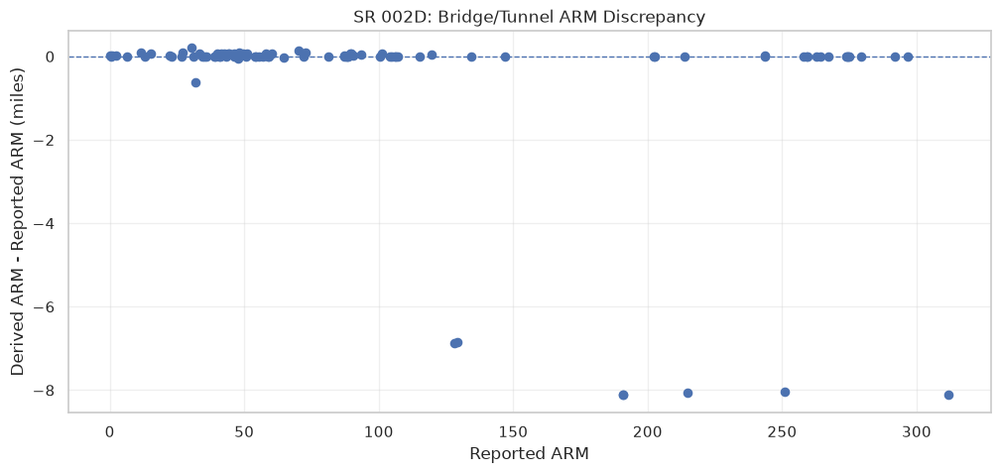

In [24]:
sr002d = sr002d.sort_values("reported_arm").copy()

fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(
    sr002d["reported_arm"],
    sr002d["arm_difference_miles"],
    s=35
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("SR 002D: Bridge/Tunnel ARM Discrepancy")
ax.set_xlabel("Reported ARM")
ax.set_ylabel("Derived ARM - Reported ARM (miles)")
ax.grid(True, alpha=0.3)

plt.show()

# Exploratory section only; these boundaries are based on the
# observed cluster and are not official calibration boundaries.

section_002d = sr002d[
    sr002d["reported_arm"].between(190, 312)
].copy()

offset = section_002d["arm_difference_miles"].median()

section_002d["normalized_discrepancy"] = (
    section_002d["arm_difference_miles"] - offset
)

print(f"Section median offset: {offset:.4f} miles")
print(f"Records in section: {len(section_002d)}")

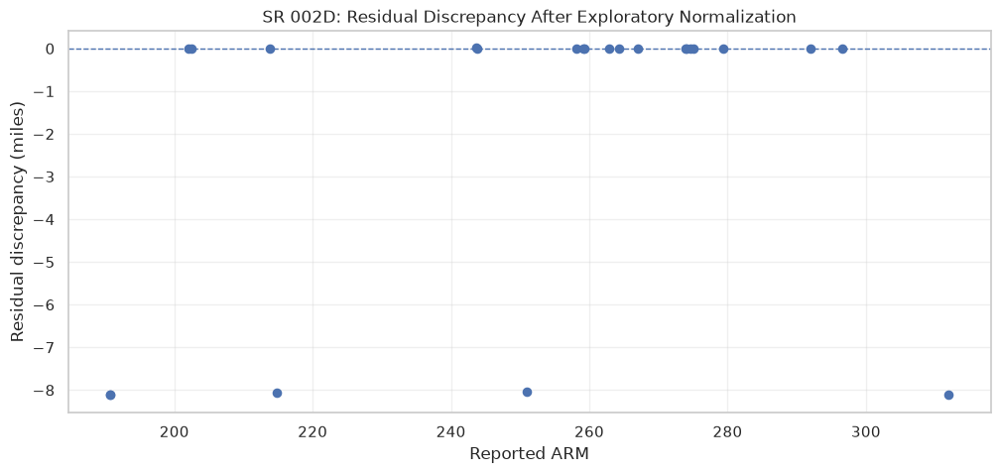

In [26]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(
    section_002d["reported_arm"],
    section_002d["normalized_discrepancy"],
    s=35
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("SR 002D: Residual Discrepancy After Exploratory Normalization")
ax.set_xlabel("Reported ARM")
ax.set_ylabel("Residual discrepancy (miles)")
ax.grid(True, alpha=0.3)

plt.show()

In [27]:
m_normalized = section_002d.explore(
    column="normalized_discrepancy",
    cmap="RdYlBu",
    tooltip=[
        "structurenumber",
        "reported_arm",
        "derived_arm",
        "arm_difference_miles",
        "normalized_discrepancy",
        "distance_to_route"
    ],
    name="Normalized residual discrepancy",
    marker_kwds={"radius": 5}
)

m_normalized

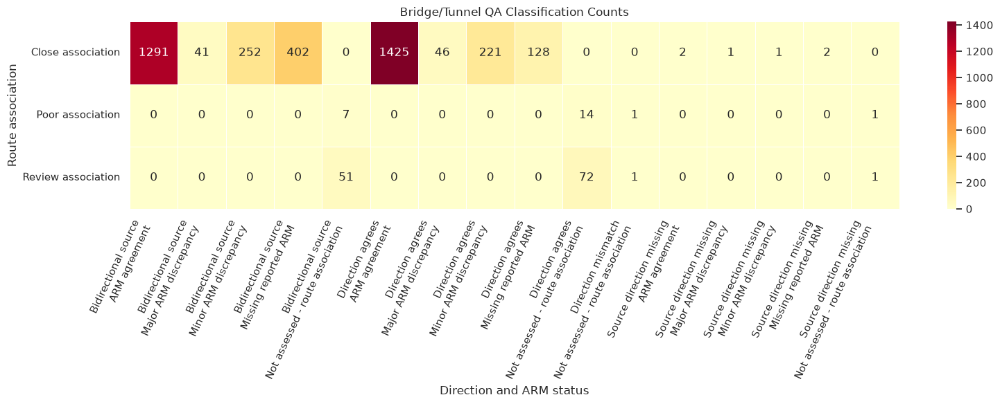

In [28]:

sql = """
SELECT
    route_association_status,
    direction_status,
    arm_agreement_status,
    COUNT(*) AS record_count
FROM qa.vw_bt_qa_dimensions
GROUP BY
    route_association_status,
    direction_status,
    arm_agreement_status
ORDER BY
    route_association_status,
    direction_status,
    arm_agreement_status;
"""

qa_summary = query_df(sql)

# Consistent ordering for readability
route_order = [
    "Close association",
    "Review association",
    "Poor association"
]

direction_order = [
    "Direction agrees",
    "Bidirectional source",
    "Direction mismatch",
    "Source direction missing",
    "Matched direction missing"
]

arm_order = [
    "ARM agreement",
    "Minor ARM discrepancy",
    "Major ARM discrepancy",
    "Not assessed - direction",
    "Not assessed - route association",
    "Missing reported ARM",
    "Missing derived ARM"
]

qa_summary["direction_arm"] = (
    qa_summary["direction_status"]
    + "\n"
    + qa_summary["arm_agreement_status"]
)

qa_summary = qa_summary[qa_summary['route_association_status'] != 'No route match']
heatmap_data = qa_summary.pivot(
    index="route_association_status",
    columns="direction_arm",
    values="record_count"
).fillna(0)

plt.figure(figsize=(16, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5,
    linecolor="white"
)

plt.title("Bridge/Tunnel QA Classification Counts")
plt.xlabel("Direction and ARM status")
plt.ylabel("Route association")
plt.xticks(rotation=65, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

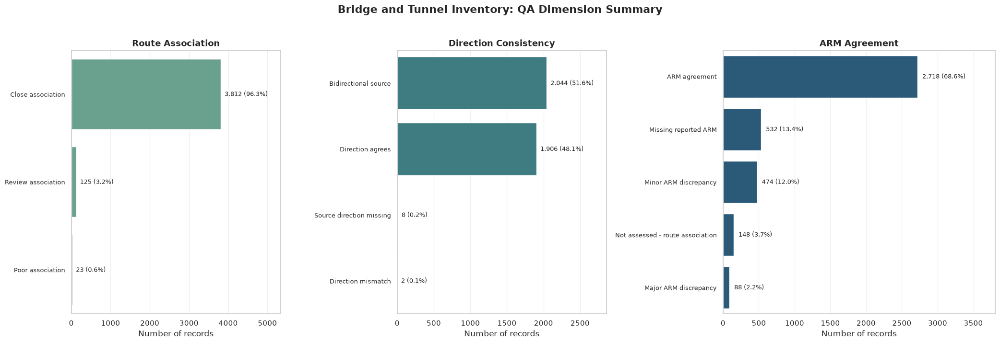

In [29]:
# SQL queries
queries = [
    (
        "Route Association",
        "route_association_status",
        """
        SELECT
            route_association_status,
            COUNT(*) AS record_count,
            ROUND(
                100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
                1
            ) AS percent_of_records
        FROM qa.vw_bt_qa_dimensions
        WHERE route_association_status != 'No route match'
        GROUP BY route_association_status
        ORDER BY record_count DESC;
        """
    ),
    (
        "Direction Consistency",
        "direction_status",
        """
        SELECT
            direction_status,
            COUNT(*) AS record_count,
            ROUND(
                100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
                1
            ) AS percent_of_records
        FROM qa.vw_bt_qa_dimensions
        WHERE route_association_status != 'No route match'
        GROUP BY direction_status
        ORDER BY record_count DESC;
        """
    ),
    (
        "ARM Agreement",
        "arm_agreement_status",
        """
        SELECT
            arm_agreement_status,
            COUNT(*) AS record_count,
            ROUND(
                100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
                1
            ) AS percent_of_records
        FROM qa.vw_bt_qa_dimensions
        WHERE route_association_status != 'No route match'
        GROUP BY arm_agreement_status
        ORDER BY record_count DESC;
        """
    )
]

# Plot setup
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    1, 3,
    figsize=(21, 7),
    gridspec_kw={"width_ratios": [1, 1, 1.3]}
)

palette = sns.color_palette("crest", 3)

# Generate each plot
for ax, (title, status_col, sql), color in zip(axes, queries, palette):

    df = query_df(sql)

    sns.barplot(
        data=df,
        x="record_count",
        y=status_col,
        order=df[status_col].tolist(),
        color=color,
        ax=ax
    )

    # Add count and percentage labels
    max_count = df["record_count"].max()

    for patch, (_, row) in zip(ax.patches, df.iterrows()):
        ax.text(
            patch.get_width() + max_count * 0.025,
            patch.get_y() + patch.get_height() / 2,
            f"{int(row['record_count']):,} ({row['percent_of_records']:.1f}%)",
            va="center",
            fontsize=9
        )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Number of records")
    ax.set_ylabel("")
    ax.set_xlim(0, max_count * 1.4)
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(axis="x", alpha=0.3)
    ax.grid(axis="y", visible=False)

fig.suptitle(
    "Bridge and Tunnel Inventory: QA Dimension Summary",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

In [39]:
sql_within_route = """
WITH eligible AS (
    SELECT
        route_identifier,
        matched_direction,
        arm_difference_miles AS difference
    FROM qa.vw_bt_qa_dimensions
    WHERE arm_agreement_status IN (
        'ARM agreement',
        'Minor ARM discrepancy',
        'Major ARM discrepancy'
    )
    AND route_identifier IS NOT NULL
    AND arm_difference_miles IS NOT NULL
),

route_medians AS (
    SELECT
        route_identifier,
        matched_direction,
        COUNT(*) AS structure_count,
        percentile_cont(0.5)
            WITHIN GROUP (ORDER BY difference) AS median_difference
    FROM eligible
    GROUP BY route_identifier, matched_direction
    HAVING COUNT(*) >= 5
),

residuals AS (
    SELECT
        e.route_identifier,
        e.matched_direction,
        e.difference - r.median_difference AS centered_difference
    FROM eligible e
    JOIN route_medians r
        ON e.route_identifier = r.route_identifier
        AND e.matched_direction IS NOT DISTINCT FROM r.matched_direction
)

SELECT
    COUNT(*) AS structure_count,
    COUNT(DISTINCT (route_identifier, matched_direction))
        AS route_direction_groups,

    ROUND(
        (STDDEV_SAMP(centered_difference) * 5280)::numeric, 1
    ) AS within_route_stddev_ft,

    ROUND(
        (AVG(ABS(centered_difference)) * 5280)::numeric, 1
    ) AS mean_absolute_residual_ft,

    ROUND(
        (percentile_cont(0.5)
            WITHIN GROUP (ORDER BY ABS(centered_difference)) * 5280)::numeric, 1
    ) AS median_absolute_residual_ft,

    ROUND(
        (percentile_cont(0.90)
            WITHIN GROUP (ORDER BY ABS(centered_difference)) * 5280)::numeric, 1
    ) AS p90_absolute_residual_ft

FROM residuals;
"""

sql = """
WITH eligible AS (
    SELECT
        route_identifier,
        matched_direction,
        arm_difference_miles AS difference
    FROM qa.vw_bt_qa_dimensions
    WHERE arm_agreement_status IN (
        'ARM agreement',
        'Minor ARM discrepancy',
        'Major ARM discrepancy'
    )
    AND route_identifier IS NOT NULL
    AND arm_difference_miles IS NOT NULL
)
SELECT
    COUNT(*) AS structure_count,

    -- Signed difference: derived ARM minus reported ARM
    ROUND(
        (AVG(difference) * 5280)::numeric, 1
    ) AS mean_signed_difference_ft,

    ROUND(
        (percentile_cont(0.5)
            WITHIN GROUP (ORDER BY difference) * 5280)::numeric, 1
    ) AS median_signed_difference_ft,

    ROUND(
        (STDDEV_SAMP(difference) * 5280)::numeric, 1
    ) AS standard_deviation_ft,

    -- Absolute differences
    ROUND(
        (AVG(ABS(difference)) * 5280)::numeric, 1
    ) AS mean_absolute_difference_ft,

    ROUND(
        (percentile_cont(0.5)
            WITHIN GROUP (ORDER BY ABS(difference)) * 5280)::numeric, 1
    ) AS median_absolute_difference_ft,

    -- Root mean square error
    ROUND(
        (SQRT(AVG(difference * difference)) * 5280)::numeric, 1
    ) AS rmse_ft,

    -- Upper-tail discrepancy
    ROUND(
        (percentile_cont(0.90)
            WITHIN GROUP (ORDER BY ABS(difference)) * 5280)::numeric, 1
    ) AS p90_absolute_difference_ft,

    ROUND(
        (percentile_cont(0.95)
            WITHIN GROUP (ORDER BY ABS(difference)) * 5280)::numeric, 1
    ) AS p95_absolute_difference_ft,

    -- Percentage within exploratory thresholds
    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE ABS(difference) <= 0.01
        ) / COUNT(*), 1
    ) AS pct_within_001_mi,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE ABS(difference) <= 0.05
        ) / COUNT(*), 1
    ) AS pct_within_005_mi,

    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE ABS(difference) <= 0.10
        ) / COUNT(*), 1
    ) AS pct_within_010_mi

FROM eligible;
"""

arm_summary = query_df(sql)
within_route_summary = query_df(sql_within_route)

# Combine both summaries horizontally
summary_comparison = pd.concat(
    [
        arm_summary.add_prefix("overall_"),
        within_route_summary.add_prefix("within_route_")
    ],
    axis=1
)

# Show all columns
pd.set_option("display.max_columns", None)

display(summary_comparison.T)

,0
overall_structure_count,3280.0
overall_mean_signed_difference_ft,-2916.2
overall_median_signed_difference_ft,1.7
overall_standard_deviation_ft,169405.7
overall_mean_absolute_difference_ft,3964.2
overall_median_absolute_difference_ft,10.2
overall_rmse_ft,169405.0
overall_p90_absolute_difference_ft,127.2
overall_p95_absolute_difference_ft,309.4
overall_pct_within_001_mi,82.9


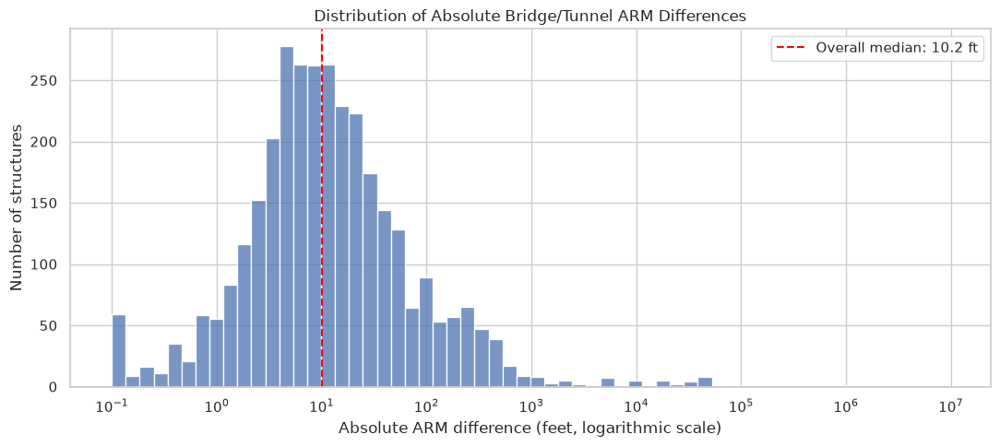

In [34]:
# Use signed ARM difference to derive absolute difference in feet
plot_data = query_df("""
SELECT
    ABS(arm_difference_miles * 5280.0) AS absolute_difference_ft
FROM qa.vw_bt_qa_dimensions
WHERE arm_agreement_status IN (
    'ARM agreement',
    'Minor ARM discrepancy',
    'Major ARM discrepancy'
)
AND route_identifier IS NOT NULL
AND arm_difference_miles IS NOT NULL;
""")

# Log scale cannot display zero, so apply a small plotting floor
plot_data["absolute_difference_ft"] = (
    plot_data["absolute_difference_ft"].clip(lower=0.1)
)

fig, ax = plt.subplots(figsize=(11, 5))

sns.histplot(
    data=plot_data,
    x="absolute_difference_ft",
    bins=60,
    log_scale=True,
    ax=ax
)

ax.axvline(
    10.2,
    color="red",
    linestyle="--",
    label="Overall median: 10.2 ft"
)

ax.set_title("Distribution of Absolute Bridge/Tunnel ARM Differences")
ax.set_xlabel("Absolute ARM difference (feet, logarithmic scale)")
ax.set_ylabel("Number of structures")
ax.legend()

plt.tight_layout()
plt.show()

# Dig Once - Broadband Utilities

‘Dig once’ is a collaborative approach for broadband utility providers to install conduit and fiber concurrently with highway construction projects.
## Process for participating in a ‘Dig Once’ project
### Find a ‘dig once’ opportunity
1. Sign up for email alerts through the GovDelivery subscription service for Dig Once - Broadband Utilities
2. Search for ‘dig once’ opportunities by using our Dig Once – Broadband Utilities Map
3. Inquire directly about a specific WSDOT project by contacting us at broadband.utilities@wsdot.wa.gov

### Coordinating with WSDOT

1. The Broadband Utility Coordinator will assist with connecting you to the project design team to confirm the project is suitable for ‘dig once’ and further coordination.
2. The WSDOT project team will confirm if ‘dig once’ is feasible.
3. A signed Utility Accommodation Application (Form 224-696) is required to continue coordination with WSDOT (see Utility Accommodation Permits and Franchises for more information).

### Broadband design and construction

1. Design your broadband infrastructure to be installed concurrently with the WSDOT project in coordination with the WSDOT project team.
2. Broadband utility providers will be responsible for all costs related, but not limited to, permitting, labor, equipment, materials, and maintenance of the installation.

## Why ‘Dig Once’?

WSDOT has developed ‘dig once’ policies in response to federal and state legislation that emphasizes the importance for broadband access. The benefits of practicing this approach may include:

1. Maximizing efficiencies of the highway right of way
2. Reducing costs to install conduit and fiber
3. Minimizing disruptions to the travelling public
4. Reducing the number of excavations within the highway right of way   

For more information see  23 CFR 645.307 and RCW 47.44.160 

## Which WSDOT projects have ‘Dig Once’ opportunities?

Not all WSDOT projects are conducive to this type of collaboration. Coordination will be needed directly with the WSDOT regional project and utility staff to determine feasibility.

The projects portrayed on the Dig Once – Broadband Utilities Map are part of the WSDOT Project Delivery Plan and include projects that are most likely to be available for ‘dig once’ collaboration, including:

1. Improvement (e.g. highway widening)
2. Preservation (e.g. repaving a section of highway)
3. Traffic Operations (e.g. changeable message sign or traffic cameras)

[Source](https://wsdot.wa.gov/engineering-standards/design-topics/utilities-railroad-agreements/dig-once-broadband-utilities)

### WSDOT Current Project Delivery Plan

[Feature Service](https://data.wsdot.wa.gov/arcgis/rest/services/Shared/WSDOTProjectDeliveryPlanCurrent/FeatureServer)


In [92]:
url = "https://data.wsdot.wa.gov/arcgis/rest/services/Shared/WSDOTProjectDeliveryPlanCurrent/FeatureServer/0"

___

In [56]:
# All WSDOT projects
WSDOT = gis_package.download_feature_layer(url)

In [67]:
# full geodataframe
WSDOT

,geometry,ObjectId,ProjectNumber,ProjectTitle,WorkDescription,BookDescription,LastUpdated,CPMSRegionCode,RegionDesc,CountyName,LegDistrict,ProgramCode,ProgramDesc,ProgramDomain,SubProgramCode,SubProgramDesc,SubProgramDomain,SubCategoryCode,SubCategoryDesc,SubCategoryDomain,ImprovementTypeCode,ImprovementTypeDesc,ImpTypeDomain,ProjDef,BeginPE,EnvirDoc,RWCert,AdDate,OperComplete,TotalDollars,RouteIdentifier,StateRouteNumber,RelatedRouteType,RelatedRouteQualifier,BeginStateRouteMilePost,EndStateRouteMilePost,MiddleStateRouteMilePost,BeginAccumulatedRouteMile,EndAccumulatedRouteMile,MiddleAccumulatedRouteMile,InventoryDirection,ARMCalcResponseDate,Longitude,Latitude,Shape__Length,source
0,"MULTILINESTRING ((-117.62051 48.06008, -117.62...",1,629200U,SR 292/Springdale to Loon Lake - Chip Seal,Chip Seal,The existing pavement is deteriorating due to ...,1361347200000,ER,Eastern,Stevens,07,P,Preservation,P - Preservation,P1,Roadway Preservation,P1 - Roadway Preservation,PA,Paving,PA - Paving,L,Chip Seal (aka BST) -,L - Chip Seal (aka BST) -,1.616742e+12,1.618384e+12,1.660720e+12,NaN,1.665990e+12,1.694156e+12,780017,292,292,,,0.000000,5.910000,2.960000,0.000000,5.910000,2.960000,B,1704009600000,-117.681362,48.063846,3.134772e+04,FeatureServer
1,"MULTILINESTRING ((-122.32428 47.45111, -122.32...",2,150907G,SR 509/28th/24th Ave S to S 188th St - SR 509 ...,Widening and Toll Lanes,This project will widen SR 509 between 24th/28...,1523430000000,GWP,Gateway Projects,King,33,I,Improvement,I - Improvement,I1,Mobility,I1 - Mobility,IA,Urban Mobility,IA - Urban Mobility,BI,Urban Mobility - Interchange New or Rebuild,BI - Urban Mobility - Interchange New or Rebuild,1.500880e+12,1.606205e+12,1.650524e+12,1.687417e+12,1.677744e+12,1.848640e+12,651476886,509,509,,,21.490000,24.200001,22.850000,25.240000,29.000000,27.120001,B,1704009600000,-122.333930,47.446034,2.465234e+04,FeatureServer
2,"MULTILINESTRING ((-117.57752 47.58006, -117.57...",3,609047C,I-90/Medical Lake I/C to Geiger Field I/C - Re...,Design and rebuild I/C for Exit 272.,Increasing private and commercial development ...,1361347200000,ER,Eastern,Spokane,06,I,Improvement,I - Improvement,I1,Mobility,I1 - Mobility,IA,Urban Mobility,IA - Urban Mobility,BI,Urban Mobility - Interchange New or Rebuild,BI - Urban Mobility - Interchange New or Rebuild,1.453277e+12,1.504163e+12,1.536217e+12,1.550477e+12,1.553497e+12,1.624000e+12,20546380,090,090,,,271.809998,277.260010,274.540009,269.519989,274.970001,272.250000,B,1704009600000,-117.534098,47.605499,5.750088e+04,FeatureServer
3,"LINESTRING (-122.67505 45.61812, -122.67298 45...",4,400019P,Clark County I-5 Ramp Paving,Rehabilitate ramps with hot mix asphalt overla...,Resurfaces deteriorating asphalt pavement on s...,1513929600000,SWR,Southwest,Clark,49,P,Preservation,P - Preservation,P1,Roadway Preservation,P1 - Roadway Preservation,PA,Paving,PA - Paving,F,Hot Mix Asphalt (aka ACP),F - Hot Mix Asphalt (aka ACP),1.513843e+12,1.519373e+12,1.762762e+12,NaN,NaN,NaN,12661,005,005,,,0.000000,13.229999,6.620000,0.000000,13.229999,6.620000,,1704009600000,-122.652984,45.709404,6.987755e+04,FeatureServer
4,"LINESTRING (-122.31687 47.39468, -122.31637 47...",5,151601A,SR 516 Barnes Creek - Fish Passage,Remove fish barrier (ID# 991191),Remove the existing fish passage barrier and r...,1516262400000,NWR,Northwest,King,33,I,Improvement,I - Improvement,I4,Environmental Retrofit,I4 - Environmental Retrofit,IL,Fish Barriers,IL - Fish Barriers,P1,Fish Barrier Retrofit,P1 - Fish Barrier Retrofit,1.520323e+12,1.530083e+12,1.604041e+12,1.658387e+12,1.661756e+12,1.695625e+12,4732040,516,516,,,0.390000,0.430000,0.410000,0.390000,0.430000,0.410000,B,1704009600000,-122.316425,47.394706,2.136648e+02,FeatureServer
5,"LINESTRING (-119.02518 46.21735, -119.02379 46...",6,501218F,US 12/Snake River Vaughn Hubbard Bridge EB - R...,Repair Floor Beams Bridge 12/512S,The existing steel floor beams on the eastboun...,1517126400000,SCR,South Central,"Franklin, Walla Walla",16,P,Pres

In [58]:
# Extract current WSDOT dig once definition from query on current WSDOT project delivery feature service
where_clause = (
    "(AdDate > timestamp '2025-01-01 07:59:59') AND "
    "(ProgramCode = 'I' OR ProgramCode = 'P' OR ProgramCode = 'Q')"
)

# Load as geodataframe
dig_once = gis_package.download_feature_layer(url, where=where_clause)

DO_projects = gdf_wsdot["ProjectNumber"].tolist()

___

### Quick Analysis of Dig Once Locations
- Total distance per project type
- Total cost per project type
- Total cost per mile for each project type

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

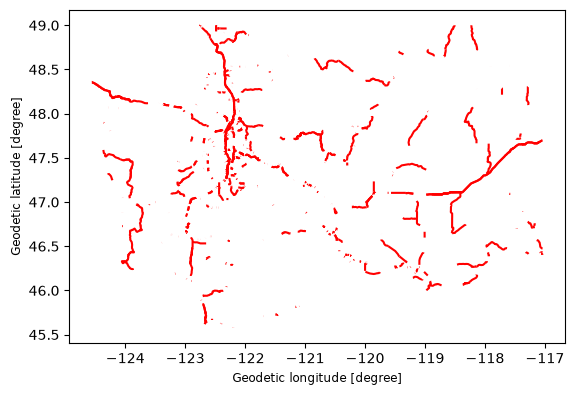

In [93]:
dig_once.explore(color='Red')

In [ ]:
['BI - Urban Mobility - Interchange New or Rebuild', 

In [91]:
DO_description = (dig_once.groupby("ImpTypeDomain")
                  .agg(number_of_projects=("ObjectId", "count"),
                       miles=("Shape__Length", lambda n: round(sum(n) / 5280, 2)),
                      cost = ("TotalDollars", lambda n: round(sum(n), 2))))
DO_description['cost_per_mile'] = DO_description['cost'] / DO_description['miles']
DO_description.sort_values('cost_per_mile', ascending=False)

,number_of_projects,miles,cost,cost_per_mile
ImpTypeDomain,,,,
EM - Special Bridge Repair (Movable),1,0.07,14544096,2.077728e+08
8U - At Grade Intersections (Urban) - (NHS Multi-lane>45 mph),1,0.02,2709573,1.354786e+08
AM - Access Management,1,0.14,7057646,5.041176e+07
P3 - Noise Barrier Retrofit,1,0.26,10678043,4.106940e+07
DO - Bridge Replacement (Functionally Obsolete),1,0.30,10000000,3.333333e+07
ZS - Bridge Rehabilitation (Structural) also Concrete Br. Deck Repl.,9,2.33,64117845,2.751839e+07
TZ - ITS / Traveler Information Systems,1,0.01,217702,2.177020e+07
{C - Major Drainage Rehabilitation (Culvert Replacement),8,0.80,16095762,2.011970e+07
BI - Urban Mobility - Interchange New or Rebuild,16,61.32,1164384973,1.898867e+07


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

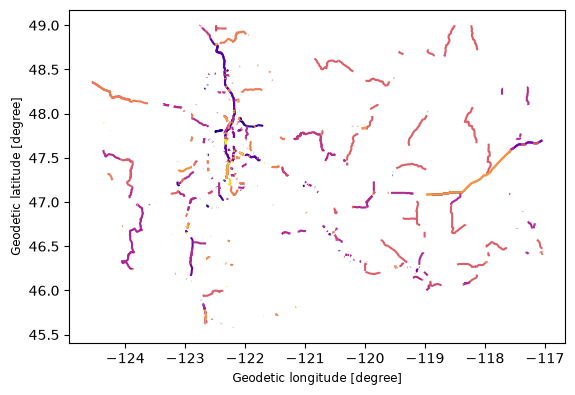

In [94]:
dig_once.explore(column='ImpTypeDomain', cmap='plasma')